# FunnelScope — exploration, sizing and significance

This notebook is where the analysis was *worked out*. The conclusions live in
[`docs/MEMO.md`](../docs/MEMO.md); the reusable logic lives in `funnelscope/`, so nothing
here re-implements a calculation the memo or the dashboard depends on.

**Run order:** `scripts/run_queries.py` (or `scripts/make_fixture.py`) → this notebook.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from funnelscope import FUNNEL_STAGES, STAGE_LABELS, funnel, io as fio, retention, rice, sizing
from funnelscope.stats import ProportionTest

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

manifest = fio.read_manifest()
print(manifest.banner())

[SYNTHETIC FIXTURE] THESE NUMBERS ARE FROM A SYNTHETIC FIXTURE, NOT FROM GA4. They exist so the pipeline can be executed and tested end to end without GCP credentials. They describe nothing about Google's demo store and must not be quoted as findings. Run `python scripts/run_queries.py` to replace them.


## 0. Provenance check

Before anything else: where did these numbers come from? If the banner above says
**synthetic fixture**, nothing below describes real user behaviour and no conclusion
drawn here may be quoted.

## 1. What is in the window

The first question for any event dataset is whether it actually contains the events the
analysis assumes. A funnel built on an event that fires 200 times is not a funnel.

In [2]:
overview = fio.load("01_event_overview")
overview.sort_values("events", ascending=False)

,event_name,events,users,first_date,last_date
0,view_item,60000,60000,2020-11-01,2021-02-01
1,first_visit,42536,42536,2020-11-01,2021-02-01
2,session_start,24688,19400,2020-11-01,2021-02-01
3,add_to_cart,15798,15798,2020-11-01,2021-02-01
4,begin_checkout,6997,6997,2020-11-01,2021-02-01
5,purchase,4134,4134,2020-11-01,2021-02-01


In [3]:
funnel_events = ["view_item", "add_to_cart", "begin_checkout", "purchase"]
missing = set(funnel_events) - set(overview.event_name)
assert not missing, f"funnel events absent from the window: {missing}"
print("All four funnel events present.")
print(f"Date coverage: {overview.first_date.min()} to {overview.last_date.max()}")
print(f"Total events: {overview.events.sum():,}")

All four funnel events present.
Date coverage: 2020-11-01 to 2021-02-01
Total events: 154,153


## 2. The funnel, and the gate before it

Two independent implementations, run against each other before any number is used.
This is the step most portfolio analyses skip, and funnel SQL is easy to get subtly
wrong in ways that never raise an error — they just quietly produce a better-looking
conversion rate.

In [4]:
overall = fio.load("02_funnel_overall")
validation = fio.load("02b_funnel_validation")

funnel.check_monotonic(overall)
funnel.cross_validate(overall, validation)

,stage,method_a_timestamps,method_b_sequence,abs_diff,rel_diff,within_tolerance
0,viewed,60000,60000,0,0.0000,True
1,added_to_cart,15798,15798,0,0.0000,True
2,began_checkout,6997,6997,0,0.0000,True
3,purchased,4134,4134,0,0.0000,True


In [5]:
row = overall.iloc[0]
rates = funnel.with_rates(overall).iloc[0]

for t in funnel.transitions(row):
    print(f"{STAGE_LABELS[t.from_stage]:>16} -> {STAGE_LABELS[t.to_stage]:<16} "
          f"{t.step_conversion:6.1%}   lost {t.lost:>8,}")

print(f"\nEnd to end: {row.purchased / row.viewed:.2%}")
worst = funnel.worst_step(row)
print(f"Steepest step: {STAGE_LABELS[worst.from_stage]} -> {STAGE_LABELS[worst.to_stage]}")

  Viewed an item -> Added to cart     26.3%   lost   44,202
   Added to cart -> Began checkout    44.3%   lost    8,801
  Began checkout -> Purchased         59.1%   lost    2,863

End to end: 6.89%
Steepest step: Viewed an item -> Added to cart


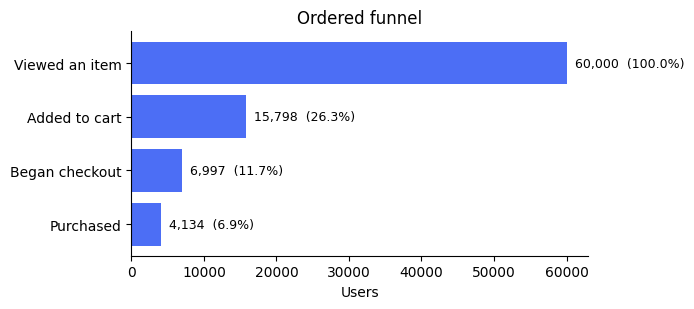

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
users = [int(row[s]) for s in FUNNEL_STAGES]
ax.barh([STAGE_LABELS[s] for s in FUNNEL_STAGES][::-1], users[::-1], color="#4C6EF5")
for i, v in enumerate(users[::-1]):
    ax.text(v, i, f"  {v:,}  ({v / users[0]:.1%})", va="center", fontsize=9)
ax.set_xlabel("Users")
ax.set_title("Ordered funnel")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 3. Segments — where the aggregate hides the finding

An aggregate funnel is almost never actionable. The cuts are where the recommendation
comes from.

In [7]:
by_device = fio.load("03_funnel_by_device")
by_source = fio.load("04_funnel_by_source")
by_visitor = fio.load("05_funnel_by_visitor_type")

for name, df in [("Device", by_device), ("Visitor type", by_visitor)]:
    d = df.copy()
    d["conversion"] = d.purchased / d.viewed
    print(f"\n{name}")
    print(d[["segment_value", "viewed", "purchased", "conversion"]].to_string(index=False))


Device
segment_value  viewed  purchased  conversion
       mobile   31383       1309      0.0417
      desktop   24503       2569      0.1048
       tablet    4114        256      0.0622

Visitor type
segment_value  viewed  purchased  conversion
          new   42536       1830      0.0430
    returning   17464       2304      0.1319


### Is the gap real, or is it sampling variation?

With tens of thousands of users almost anything is significant, and the test feels like a
formality. It stops being one on the small segments — a tablet cohort, a 600-user channel
— which is exactly where an unguarded analysis manufactures findings.

In [8]:
dev = by_device.sort_values("viewed", ascending=False)
a, b = dev.iloc[0], dev.iloc[1]
test = ProportionTest(str(a.segment_value), str(b.segment_value),
                      int(a.purchased), int(a.viewed),
                      int(b.purchased), int(b.viewed))
print(test.verdict())

mobile converts 6.31pp lower than desktop (4.17% vs 10.48%). z = -29.14, p = 1.03e-186, 95% CI [-6.76, -5.87]pp. Real, not sampling noise.


In [9]:
# Every device pair, including the small ones, so the small-n case is visible.
import itertools

for x, y in itertools.combinations(dev.itertuples(), 2):
    t = ProportionTest(str(x.segment_value), str(y.segment_value),
                       int(x.purchased), int(x.viewed),
                       int(y.purchased), int(y.viewed))
    print(("SIG " if t.significant else "n.s.") + " " + t.verdict())
    print()

SIG  mobile converts 6.31pp lower than desktop (4.17% vs 10.48%). z = -29.14, p = 1.03e-186, 95% CI [-6.76, -5.87]pp. Real, not sampling noise.

SIG  mobile converts 2.05pp lower than tablet (4.17% vs 6.22%). z = -6.03, p = 1.67e-09, 95% CI [-2.82, -1.28]pp. Real, not sampling noise.

SIG  desktop converts 4.26pp higher than tablet (10.48% vs 6.22%). z = 8.48, p = 2.25e-17, 95% CI [+3.43, +5.09]pp. Real, not sampling noise.



### Channels: two different problems that look alike

High volume with low conversion is an expectation-mismatch or targeting problem.
Low volume with high conversion is a scale opportunity. A single ranked table blurs them,
so plot volume against rate.

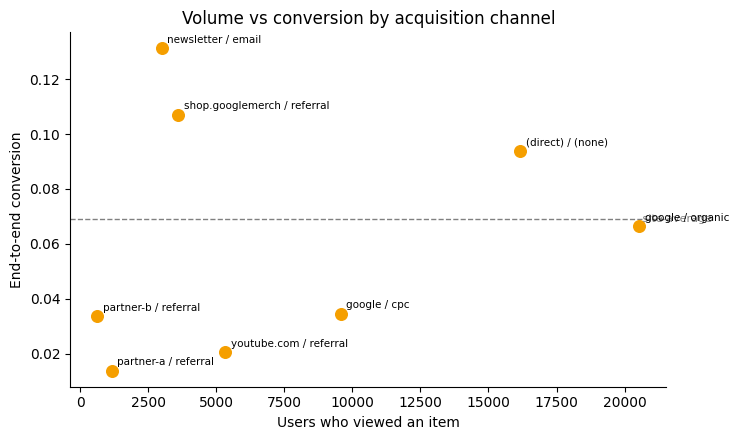

In [10]:
src = by_source[by_source.segment_value != "(long tail)"].copy()
src["conversion"] = src.purchased / src.viewed

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(src.viewed, src.conversion, s=70, color="#F59F00", zorder=3)
overall_conv = row.purchased / row.viewed
ax.axhline(overall_conv, ls="--", lw=1, color="grey")
ax.text(src.viewed.max(), overall_conv, " site average", va="center", fontsize=8, color="grey")
for _, r in src.iterrows():
    ax.annotate(r.segment_value, (r.viewed, r.conversion), fontsize=7.5,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Users who viewed an item")
ax.set_ylabel("End-to-end conversion")
ax.set_title("Volume vs conversion by acquisition channel")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. Opportunity sizing — and what it can and cannot tell you

The model is in `funnelscope/sizing.py`, along with two corrections to the textbook form.
The second one is the interesting one: **this model cannot re-rank the stages.** In a
strictly ordered funnel, recoverable revenue is a monotone function of step conversion,
so ranking by dollars and ranking by worst drop-off are the same ordering by
construction. Anyone presenting them as two pieces of evidence is double-counting one
fact.

In [11]:
revenue = fio.load("07_revenue_by_segment")
aov = sizing.aov_from_revenue(revenue)
print(f"AOV (transaction-weighted): ${aov:,.2f}")

opportunities = sizing.size_all_stages(row, aov, improvement_pp=0.05)
opportunities[["from_stage", "to_stage", "users_lost", "users_recovered",
               "downstream_conversion", "recoverable_revenue"]]

AOV (transaction-weighted): $63.51


,from_stage,to_stage,users_lost,users_recovered,downstream_conversion,recoverable_revenue
0,viewed,added_to_cart,44202,"3,000.0000",0.2617,"49,860.6115"
1,added_to_cart,began_checkout,8801,789.9000,0.5908,"29,641.3988"
2,began_checkout,purchased,2863,349.8500,1.0000,"22,220.2971"


In [12]:
print("Ranking by recoverable revenue == ranking by worst step conversion:",
      sizing.ranking_matches_step_conversion(row))

# The same, using the textbook `users_lost x pp` basis, for comparison.
lost_basis = sizing.size_all_stages(row, aov, improvement_pp=0.05, basis="lost")
comparison = opportunities[["to_stage", "recoverable_revenue"]].merge(
    lost_basis[["to_stage", "recoverable_revenue"]], on="to_stage",
    suffixes=("_entering_basis", "_lost_basis"))
comparison["understatement"] = (
    1 - comparison.recoverable_revenue_lost_basis / comparison.recoverable_revenue_entering_basis)
comparison

Ranking by recoverable revenue == ranking by worst step conversion: True


,to_stage,recoverable_revenue_entering_basis,recoverable_revenue_lost_basis,understatement
0,added_to_cart,"49,860.6115","36,732.3125",0.2633
1,began_checkout,"29,641.3988","16,513.0998",0.4429
2,purchased,"22,220.2971","9,091.9981",0.5908


### Sensitivity

The absolute figures move with the improvement assumption; the ranking does not. That is
the defensible claim, and publishing the sweep is what makes it one.

In [13]:
sens = sizing.sensitivity_table(row, aov, improvements=(0.01, 0.02, 0.05, 0.10))
sens

improvement_pp,to_stage,0.0100,0.0200,0.0500,0.1000
0,added_to_cart,"9,972.1223","19,944.2446","49,860.6115","99,721.2229"
1,began_checkout,"5,928.2798","11,856.5595","29,641.3988","59,282.7977"
2,purchased,"4,444.0594","8,888.1188","22,220.2971","44,440.5941"


### The segment gap — where sizing *does* add information

Across segments at the same stage, traffic volume and downstream conversion vary in ways
step conversion alone does not capture, so this figure is not a restatement of the rate.

In [14]:
lo, hi = dev.iloc[0], dev.iloc[1]
if (lo.purchased / lo.viewed) > (hi.purchased / hi.viewed):
    lo, hi = hi, lo
gap = sizing.segment_gap_value(lo, hi, aov)
for k, v in gap.items():
    print(f"{k:>32}: {v:,.4f}" if isinstance(v, float) else f"{k:>32}: {v}")

                       segment_a: mobile
                       segment_b: desktop
                    conversion_a: 0.0417
                    conversion_b: 0.1048
                          gap_pp: 6.3134
  additional_purchases_if_closed: 1,981.3288
                 value_if_closed: 125,841.6890


## 5. Retention, with censoring handled

The trap: a cohort formed in the final weeks of a fixed window physically cannot show
later-week retention. Read naively, those empty cells look like a retention collapse.
They are right-censored.

In [15]:
cohorts = fio.load("06_cohort_retention")
last_date = pd.to_datetime(overview.last_date).max()
coh = retention.mark_censored(cohorts, last_date)

summary = retention.censoring_summary(coh)
print(f"{summary['cells_censored']} of {summary['cells_total']} cells "
      f"({summary['share_censored']:.0%}) are censored and excluded.")
print("Maximum observable week per cohort:")
for k, v in summary["max_observable_week_by_cohort"].items():
    print(f"  {k}: W{v}")

2 of 78 cells (3%) are censored and excluded.
Maximum observable week per cohort:
  2020-11-01: W7
  2020-11-08: W7
  2020-11-15: W7
  2020-11-22: W7
  2020-11-29: W7
  2020-12-06: W7
  2020-12-13: W6
  2020-12-20: W5
  2020-12-27: W4
  2021-01-03: W3
  2021-01-10: W2
  2021-01-17: W1
  2021-01-24: W0


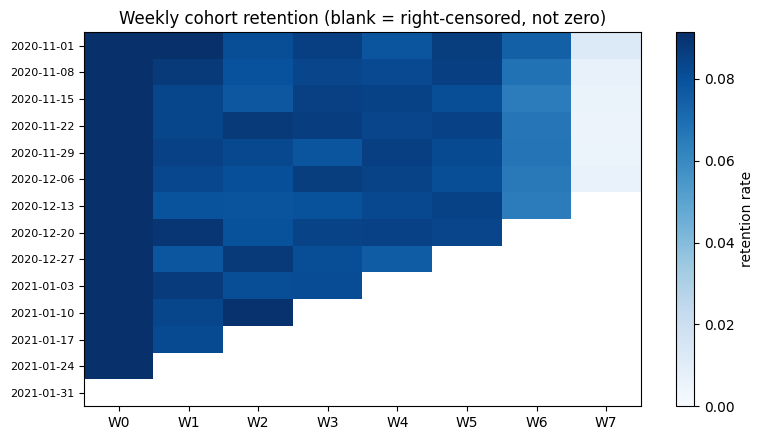

In [16]:
m = retention.matrix(coh)

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(m.values, cmap="Blues", aspect="auto", vmin=0, vmax=float(m.iloc[:, 1:].max().max() or 1))
ax.set_xticks(range(len(m.columns)), [f"W{c}" for c in m.columns])
ax.set_yticks(range(len(m.index)), [str(d) for d in m.index], fontsize=8)
ax.set_title("Weekly cohort retention (blank = right-censored, not zero)")
fig.colorbar(im, ax=ax, label="retention rate")
plt.tight_layout()

,weeks_since_first,active_users,cohort_size,cohorts_observed,retention_rate
0,0,59290,59290,13,1.0000
1,1,4741,56568,12,0.0838
2,2,4299,52031,11,0.0826
3,3,3878,46785,10,0.0829
4,4,3443,41509,9,0.0829
5,5,3003,36111,8,0.0832
6,6,2032,30658,7,0.0663
7,7,156,25279,6,0.0062


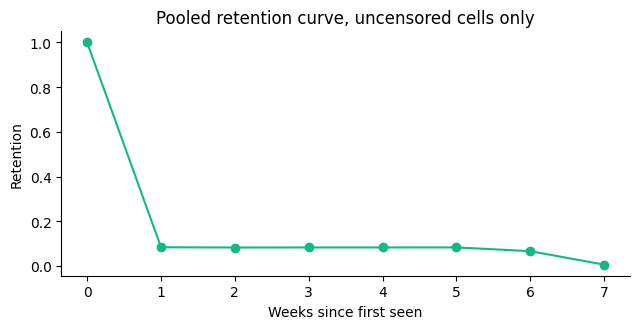

In [17]:
curve = retention.average_curve(coh)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(curve.weeks_since_first, curve.retention_rate, marker="o", color="#12B886")
ax.set_xlabel("Weeks since first seen")
ax.set_ylabel("Retention")
ax.set_title("Pooled retention curve, uncensored cells only")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
curve

## 6. RICE

Reach is measured. Impact, confidence and effort are judgement, declared in
`scripts/analyze.py::INTERVENTION_CATALOG` so a reader can change one number and watch
the ranking move. The point is a reproducible ranking, not a correct one.

In [18]:
import json
metrics = json.loads((fio.PROCESSED_DIR / "metrics.json").read_text())
ranked = pd.DataFrame(metrics["rice"])
ranked[["rank", "name", "reach", "impact", "confidence", "effort", "rice_score"]]

,rank,name,reach,impact,confidence,effort,rice_score
0,1,Rework the product page add-to-cart path on th...,"44,202.0000",2.0000,0.7000,3.0000,"20,627.6000"
1,2,Reduce cart-to-checkout friction (persistent c...,"8,801.0000",2.0000,0.6000,4.0000,"2,640.3000"
2,3,Rebalance paid spend away from the worst-conve...,"1,160.0000",1.0000,0.7500,1.5000,580.0000
3,4,Shorten the checkout form and surface total co...,"2,863.0000",1.0000,0.5500,5.0000,314.9300


In [19]:
for _, r in ranked.iterrows():
    print(f"{int(r['rank'])}. {r['name']}  (RICE {r['rice_score']:,.0f})")
    print(f"   evidence:   {r['evidence']}")
    print(f"   assumption: {r['assumptions']}\n")

1. Rework the product page add-to-cart path on the weakest device  (RICE 20,628)
   evidence:   44,202 users lost at this step; $49,861 recoverable at +5pp (upper bound).
   assumption: Assumes the gap is friction rather than a difference in visit intent by device. Untested — an A/B test on the mobile PDP settles it.

2. Reduce cart-to-checkout friction (persistent cart, single-tap checkout entry)  (RICE 2,640)
   evidence:   8,801 users lost at this step; $29,641 recoverable at +5pp (upper bound).
   assumption: Assumes abandonment is friction-driven. Price shock at the cart step would produce the same signature and needs a different fix.

3. Rebalance paid spend away from the worst-converting channel: partner-a / referral  (RICE 580)
   evidence:   1,160 users from partner-a / referral converting at 1.38% vs 6.89% overall.
   assumption: Assumes conversion, not lifetime value, is the right objective for that channel. A brand-awareness channel would be misjudged by this.

4. Shorten t

## 7. What this data cannot answer

- **Why** users leave. Event counts record behaviour, not intent or friction.
- **Cross-device journeys.** `user_pseudo_id` is per browser, so a mobile-browse /
  desktop-buy user is two users, one of whom never converts. This inflates the measured
  device gap by an unknown amount.
- **Whether any recommendation works.** Each is a hypothesis with a size attached.

Next investigations, in order: session recordings on the weakest device's product page,
a cart-abandonment exit survey, and an A/B test on the top-ranked recommendation.